## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: June 22, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 4 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Regression Models

In [1]:
# Imports 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


### Load the data as a Pandas data frame and ensure that it imported correctly.

In [2]:
path = "auto-mpg.csv"
df = pd.read_csv(path)
print(df.head(5))


    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0        130    3504          12.0          70   
1  15.0          8         350.0        165    3693          11.5          70   
2  18.0          8         318.0        150    3436          11.0          70   
3  16.0          8         304.0        150    3433          12.0          70   
4  17.0          8         302.0        140    3449          10.5          70   

   origin                   car name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


### Begin by prepping the data for modeling:


In [3]:

# Remove the car name column.
df = df.drop(columns=['car name'])

# The horsepower column values likely imported as a string data type. Figure out why and replace any strings with the column mean.
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
# Calculate the mean of the numeric values (ignoring NaN)
mean_horsepower = df['horsepower'].mean()

# Replace NaN values with the mean horsepower
df['horsepower'].fillna(mean_horsepower, inplace=True)

# Create dummy variables for the origin column.
dummies = pd.get_dummies(df['origin'], prefix='origin', drop_first=True)
# Concatenate the original DataFrame with the dummy variables
df = pd.concat([df, dummies], axis=1)

/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_63680/2104360967.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].fillna(mean_horsepower, inplace=True)


### Create a correlation coefficient matrix and/or visualization. Are there features highly correlated with mpg?



Correlation Coefficient Matrix:
                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.775396     -0.804203   -0.771437 -0.831741   
cylinders    -0.775396   1.000000      0.950721    0.838939  0.896017   
displacement -0.804203   0.950721      1.000000    0.893646  0.932824   
horsepower   -0.771437   0.838939      0.893646    1.000000  0.860574   
weight       -0.831741   0.896017      0.932824    0.860574  1.000000   
acceleration  0.420289  -0.505419     -0.543684   -0.684259 -0.417457   
model year    0.579267  -0.348746     -0.370164   -0.411651 -0.306564   
origin        0.563450  -0.562543     -0.609409   -0.453669 -0.581024   
origin_2      0.259022  -0.352861     -0.373886   -0.281258 -0.298843   
origin_3      0.442174  -0.396479     -0.433505   -0.321325 -0.440817   

              acceleration  model year    origin  origin_2  origin_3  
mpg               0.420289    0.579267  0.563450  0.259022  0.442174  
cylinders        -0.5

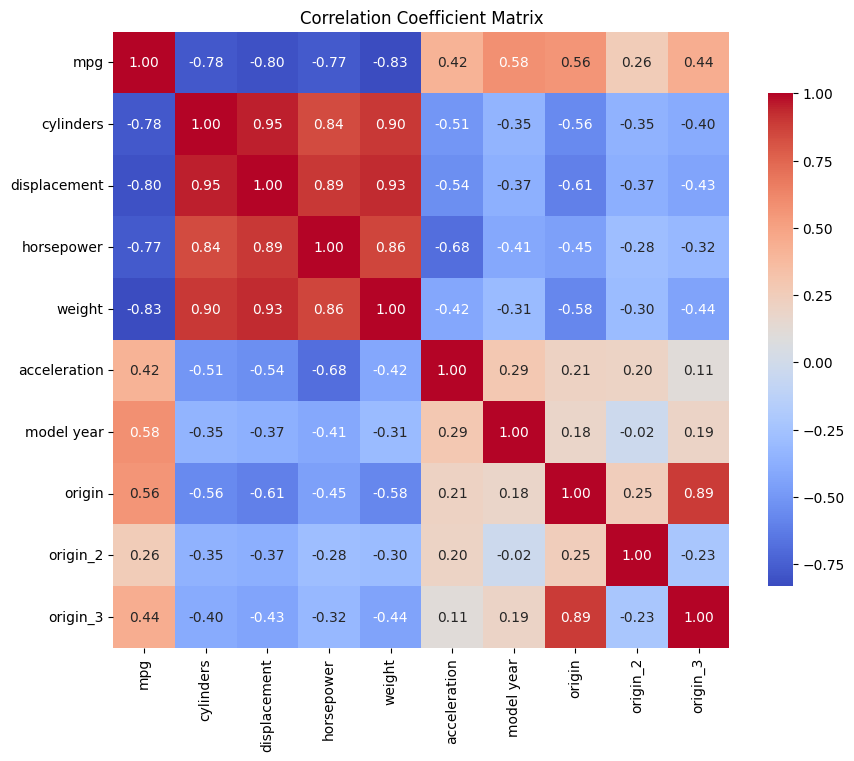


Features highly correlated with 'mpg':
mpg             1.000000
weight          0.831741
displacement    0.804203
cylinders       0.775396
horsepower      0.771437
model year      0.579267
origin          0.563450
origin_3        0.442174
acceleration    0.420289
origin_2        0.259022
Name: mpg, dtype: float64


In [4]:
correlation_matrix = df.corr()

print("\nCorrelation Coefficient Matrix:")
print(correlation_matrix)

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Correlation Coefficient Matrix')
plt.show()

# Identifying features highly correlated with 'mpg'
high_corr = correlation_matrix['mpg'].abs().sort_values(ascending=False)
print("\nFeatures highly correlated with 'mpg':")
print(high_corr)

### Plot mpg versus weight. Analyze this graph and explain how it relates to the corresponding correlation coefficient.


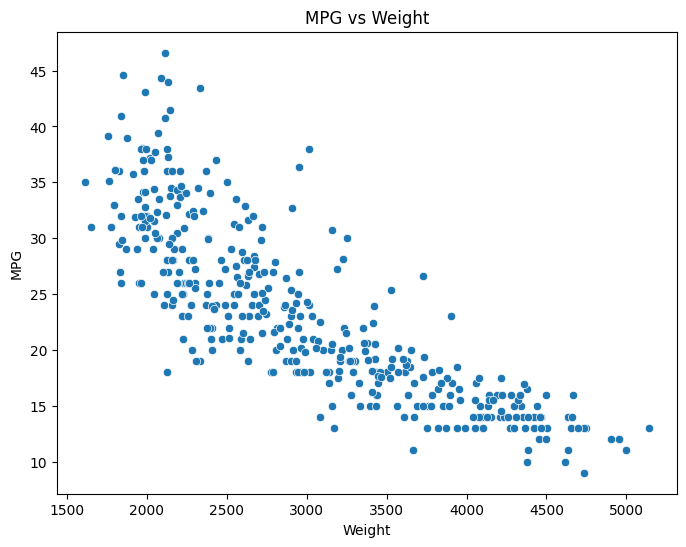

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='weight', y='mpg', data=df)
plt.title('MPG vs Weight')
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.show()

### Randomly split the data into 80% training data and 20% test data, where your target is mpg.


In [6]:

# Define features and target variable
X = df.drop(columns=['mpg'])
y = df['mpg']

# Randomly split the data into 80% training and 20% test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])


Training set size: 318
Test set size: 80


### Train an ordinary linear regression on the training data.


In [7]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

### Calculate R2, RMSE, and MAE on both the training and test sets and interpret your results.


In [8]:
# Calculate metrics for training set
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
mae_train = mean_absolute_error(y_train, y_train_pred)

# Calculate metrics for test set
r2_test = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae_test = mean_absolute_error(y_test, y_test_pred)

# Display results
print("\nTraining Set Metrics:")
print("R²:", r2_train)
print("RMSE:", rmse_train)
print("MAE:", mae_train)

print("\nTest Set Metrics:")
print("R²:", r2_test)
print("RMSE:", rmse_test)
print("MAE:", mae_test)


Training Set Metrics:
R²: 0.8188288951042786
RMSE: 3.3702735639389054
MAE: 2.605484693771036

Test Set Metrics:
R²: 0.8449006123776616
RMSE: 2.887757347883632
MAE: 2.2875867704421067


### Pick another regression model and repeat the previous two steps. Note: Do NOT choose logistic regression as it is more like a classification model.


In [9]:
# Create and train the Random Forest model
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

# Predict on training and test sets
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

# Calculate metrics for training set
r2_train_rf = r2_score(y_train, y_train_pred_rf)
rmse_train_rf = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
mae_train_rf = mean_absolute_error(y_train, y_train_pred_rf)

# Calculate metrics for test set
r2_test_rf = r2_score(y_test, y_test_pred_rf)
rmse_test_rf = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))
mae_test_rf = mean_absolute_error(y_test, y_test_pred_rf)

# Display results for Random Forest
print("\nRandom Forest Training Set Metrics:")
print("R²:", r2_train_rf)
print("RMSE:", rmse_train_rf)
print("MAE:", mae_train_rf)

print("\nRandom Forest Test Set Metrics:")
print("R²:", r2_test_rf)
print("RMSE:", rmse_test_rf)
print("MAE:", mae_test_rf)



Random Forest Training Set Metrics:
R²: 0.9806390230243949
RMSE: 1.1017532026260946
MAE: 0.7544402515723267

Random Forest Test Set Metrics:
R²: 0.9144541824472072
RMSE: 2.14464318419172
MAE: 1.6028875
